# Vuga AAC — next-symbol prediction model notebook
**Status: evidence for the existing prototype; the final project direction is under reconsideration.**

Candidate question: can a small, local next-symbol model help a Kinyarwanda picture communication board offer useful suggestions? This notebook demonstrates the existing ML pipeline, training-data engineering, model architecture and **development validation** performance. It does not establish communication benefits for real users.

The included snapshot contains all existing draft-v3 **training and validation symbol sequences**. It contains no participant data, original corpus sentences or test examples. Statistical models are refitted below; historical GRU results are clearly identified. No corpus download or neural training happens automatically.

## Run and inspect
From the repository root, activate a Python 3.11+ virtual environment, then run:

```sh
python -m pip install -e "ml[notebook]"
python ml/notebooks/run_notebook.py
```

Open this notebook in Jupyter/VS Code, or read the generated `vuga_model.html`. The runner executes every cell and saves outputs. Data are read from the committed `evidence/` snapshot, so a fresh checkout can reproduce the statistical results without the ignored raw corpus. The optional local GRU ONNX evaluation runs only when its files and snapshot hashes match. A three-seed GRU summary remains readable without model binaries.

Rebuild the snapshot only after deliberately selecting a new development iteration: `python ml/notebooks/capture_evidence.py`. See `evidence/NOTICE.md` for source and license notices.

In [1]:
from pathlib import Path
import csv
import hashlib
import importlib.metadata
import json
import math
import platform
import sys
from collections import Counter
from datetime import datetime, timezone

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Supports launching at the repository root, ml/, or ml/notebooks/.
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "ml" / "vuga_ml").is_dir())
ML = REPO / "ml"
EVIDENCE = ML / "notebooks" / "evidence"
sys.path.insert(0, str(ML))
from vuga_ml.metrics import aggregate, paired_bootstrap, score_sequence
from vuga_ml.models import KneserNeyTrigram, UnigramFrequency

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def table(headers, rows):
    lines = ["| " + " | ".join(map(str, headers)) + " |",
             "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines += ["| " + " | ".join(map(str, row)) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
COLORS = ["#0e7490", "#0f766e", "#c87928"]
RUN_UTC = datetime.now(timezone.utc).isoformat()
VERSIONS = {name: importlib.metadata.version(name)
            for name in ("numpy", "matplotlib", "nbformat", "nbclient", "onnxruntime")}
print("Executed UTC:", RUN_UTC)
print("Python:", platform.python_version())
print("Packages:", VERSIONS)

Executed UTC: 2026-09-27T22:06:25.154692+00:00
Python: 3.11.15
Packages: {'numpy': '2.4.6', 'matplotlib': '3.11.2', 'nbformat': '5.11.1', 'nbclient': '0.11.0', 'onnxruntime': '1.30.0'}


## 1. Source, integrity and partition boundaries

The raw text source is Digital Umuganda's `common_voice_dataset_rw`, identified by its local provenance record. The corpus license notice is retained in `evidence/LICENSE.corpus`; the derivation and hashes are in `evidence/PROVENANCE.json`.

The existing pipeline normalizes Unicode and letter case, standardizes apostrophes, and treats punctuation/digits as token boundaries. It accepts sentences of **2–8 input tokens** with at least **80% core-lexicon coverage**, then requires every token to map unambiguously or have an explicit DROP entry. Negation must emit a negation symbol. Output symbol lengths may differ from word lengths because one inflected word can map to multiple symbols.

Exact normalized sentence duplicates are removed. Identical symbol sequences are grouped into one partition, stratified by sequence length with seed **20260921**, targeting 80/10/10. Below, only training/validation overlap is checked; the historical test count is read from metadata.

In [2]:
provenance = read_json(EVIDENCE / "PROVENANCE.json")
for filename, expected in provenance["files_sha256"].items():
    assert sha256(EVIDENCE / filename) == expected, f"Snapshot changed: {filename}"
manifest = read_json(EVIDENCE / "split_manifest.json")
exclusions = read_json(EVIDENCE / "exclusions.json")
assert sha256(REPO / "vocab" / "lexicon_draft.csv") == manifest["lexicon_sha256"]

def load_sequences(part):
    if part not in {"train", "validation"}:
        raise ValueError("This notebook uses development partitions only.")
    return [tuple(json.loads(line)["symbols"]) for line in
            (EVIDENCE / f"{part}.jsonl").read_text(encoding="utf-8").splitlines()
            if line.strip()]

train = load_sequences("train")
validation = load_sequences("validation")
assert len(train) == manifest["train"] and len(validation) == manifest["validation"]
assert not (set(train) & set(validation)), "Symbol sequence leakage across development partitions"
assert all(train) and all(validation)
assert sum(exclusions.values()) == manifest["lines_read"]
with open(REPO / "vocab" / "symbols.csv", encoding="utf-8", newline="") as fh:
    board_rows = list(csv.DictReader(fh))
board = {row["symbol_id"]: row for row in board_rows}
train_counts = Counter(symbol for seq in train for symbol in seq)
val_counts = Counter(symbol for seq in validation for symbol in seq)
assert set(train_counts) | set(val_counts) <= set(board)

table(["Evidence", "Value"], [
    ("Corpus commit", manifest["corpus_commit"]),
    ("Lexicon SHA-256", manifest["lexicon_sha256"]),
    ("Raw lines (recorded)", f'{manifest["lines_read"]:,}'),
    ("Mapped lines before deduplication (recorded)", f'{manifest["mapped"]:,}'),
    ("Retained raw lines", f'{100 * manifest["mapped"] / manifest["lines_read"]:.3f}%'),
    ("Training sequences / symbol events", f"{len(train):,} / {sum(train_counts.values()):,}"),
    ("Validation sequences / symbol events", f"{len(validation):,} / {sum(val_counts.values()):,}"),
    ("Held-out test count (metadata only; not opened)", manifest["test"]),
    ("Board symbols / symbols observed in training", f"{len(board)} / {len(train_counts)}"),
    ("Train/validation identical-sequence overlap", 0),
])
print("Validation-only symbols:", sorted(set(val_counts) - set(train_counts)))
print("Snapshot checksums and train/validation separation: passed")

| Evidence | Value |
| --- | --- |
| Corpus commit | 2ff83be588a4b08204d2b15fbb2b0ba0a9bb1f36 |
| Lexicon SHA-256 | 182778eb23dbf7f55bc7de2769ffdbbc5bc56d4f19c5e8ba46c1a689a16af2db |
| Raw lines (recorded) | 1,698,086 |
| Mapped lines before deduplication (recorded) | 4,416 |
| Retained raw lines | 0.260% |
| Training sequences / symbol events | 2,621 / 11,506 |
| Validation sequences / symbol events | 319 / 1,398 |
| Held-out test count (metadata only; not opened) | 327 |
| Board symbols / symbols observed in training | 181 / 175 |
| Train/validation identical-sequence overlap | 0 |

Validation-only symbols: ['SHIRT']
Snapshot checksums and train/validation separation: passed


### Executable engineering example

The following short phrases are **illustrative inputs to the mapper**, not additional training or evaluation examples. The actual training data remain the frozen snapshot. The lexicon is still a generated draft awaiting native-speaker review.

In [3]:
from vuga_ml.lexicon import Lexicon
from vuga_ml.mapping import map_sentence
from vuga_ml.normalise import tokenise

lexicon = Lexicon.from_csv(REPO / "vocab" / "lexicon_draft.csv")
engineering_rows = []
for text in ["Ndashaka amazi!", "Sinshaka amazi.", "ndashaaka amazi"]:
    result = map_sentence(text, lexicon)
    engineering_rows.append((text, " ".join(tokenise(text)),
                             " + ".join(result.symbols) or "(excluded)",
                             result.status))
table(["Illustrative text", "Normalized tokens", "Mapped symbols", "Status"], engineering_rows)

| Illustrative text | Normalized tokens | Mapped symbols | Status |
| --- | --- | --- | --- |
| Ndashaka amazi! | ndashaka amazi | I + WANT + WATER | mapped |
| Sinshaka amazi. | sinshaka amazi | I + NOT + WANT + WATER | mapped |
| ndashaaka amazi | ndashaaka amazi | (excluded) | low_core_ratio |

## 2. Data visualizations

The distributions below are computed from the real frozen training/validation snapshot. Exclusion counts are recorded outputs of the earlier full-corpus preprocessing run. Low retention and a frequent-symbol imbalance constrain what these initial results can tell us about everyday AAC communication.

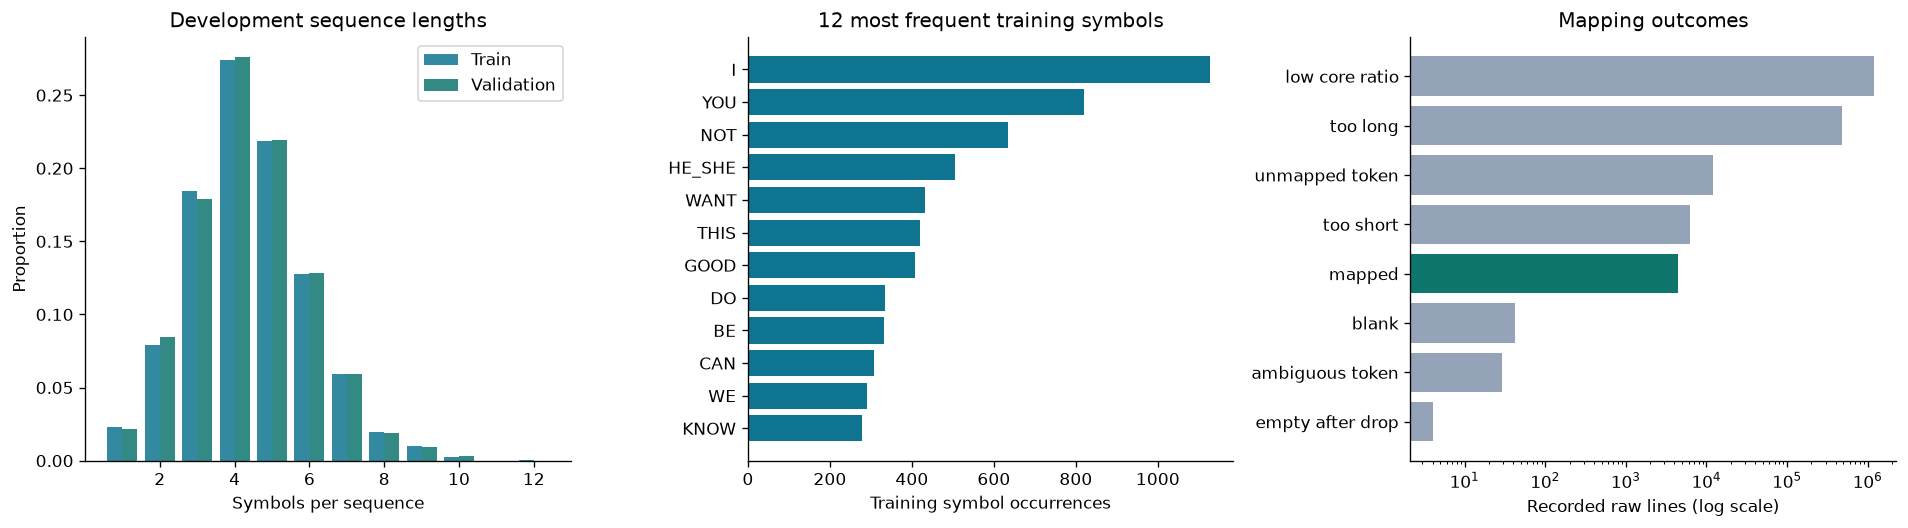

The ten most frequent symbols account for 46.2% of training events.
Training mean length: 4.39 symbols.
Validation mean length: 4.38 symbols.


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
max_length = max(map(len, train + validation))
bins = np.arange(0.5, max_length + 1.5)
axes[0].hist([list(map(len, train)), list(map(len, validation))],
             bins=bins, density=True, label=["Train", "Validation"],
             color=COLORS[:2], alpha=0.85)
axes[0].set(xlabel="Symbols per sequence", ylabel="Proportion",
            title="Development sequence lengths")
axes[0].legend()

most_common = train_counts.most_common(12)[::-1]
axes[1].barh([s for s, _ in most_common], [n for _, n in most_common], color=COLORS[0])
axes[1].set(xlabel="Training symbol occurrences", title="12 most frequent training symbols")

exclusion_items = sorted(exclusions.items(), key=lambda item: item[1])
axes[2].barh([s.replace("_", " ") for s, _ in exclusion_items],
             [n for _, n in exclusion_items],
             color=[COLORS[1] if s == "mapped" else "#94a3b8" for s, _ in exclusion_items])
axes[2].set_xscale("log")
axes[2].set(xlabel="Recorded raw lines (log scale)", title="Mapping outcomes")
fig.tight_layout()
plt.show()

top10_share = sum(n for _, n in train_counts.most_common(10)) / sum(train_counts.values())
print(f"The ten most frequent symbols account for {top10_share:.1%} of training events.")
print(f"Training mean length: {np.mean(list(map(len, train))):.2f} symbols.")
print(f"Validation mean length: {np.mean(list(map(len, validation))):.2f} symbols.")

## 3. Model architecture and training

| Model | Input and architecture | Fitting / optimization | Purpose |
| --- | --- | --- | --- |
| Unigram | One count per training symbol, including end-of-sequence | Frequency normalization; no learned layers | Context-free baseline |
| Kneser–Ney trigram | Previous two symbols → discounted trigram counts → bigram and continuation backoff | Count fitting on train; fixed absolute discount 0.75 | Small contextual model suitable for the existing local board |
| GRU | Symbol IDs → 64-dimensional embedding → one GRU layer with 128 hidden units → dropout 0.2 → linear vocabulary head | Cross-entropy ignoring padding; Adam, learning rate 0.002; batch 128; gradient norm clipping 1.0; maximum 20 epochs; validation early-stopping patience 3 | Existing compact neural experiment |

The GRU uses sigmoid reset/update gates and a tanh candidate activation; the linear head returns logits, with softmax at inference. Its output vocabulary includes every board symbol plus padding, beginning and end markers. Padding/beginning symbols are excluded by the predictor, and end-of-sequence is excluded from visible suggestions.

At each prediction position, **only the preceding symbols** are supplied. Targets are the next symbol, then end-of-sequence. The source implementations are `ml/vuga_ml/models/ngram.py`, `models/neural.py` and `metrics.py`.

The original GRU runs used seeds 0, 1, 2. This notebook shows their saved evidence and optionally evaluates the seed-0 ONNX export; it does not retrain the neural network. An older transformer run belongs to a different split and is excluded from this comparison.

| GRU layer | Shape / configuration |
| --- | --- |
| Input | batch × sequence length (integer IDs) |
| Embedding | 184 × 64 |
| GRU | 1 layer; hidden 128; sigmoid/tanh |
| Dropout | 0.2 |
| Linear | 128 → 184 logits |
| Inference | softmax; filter special tokens; rank remaining symbols |
| Trainable parameters (derived from recorded architecture) | 110,008 |

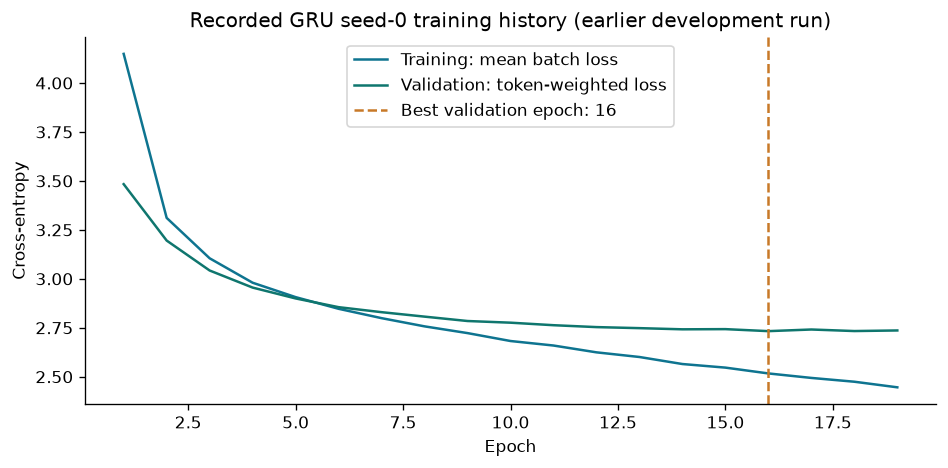

Recorded configuration: {'emb': 64, 'hidden': 128, 'layers': 1, 'dropout': 0.2, 'lr': 0.002, 'batch_size': 128, 'epochs': 20, 'patience': 3, 'seed': 0}
Training and validation curves use different averaging; compare trends cautiously.


In [5]:
gru_meta = read_json(EVIDENCE / "gru_seed0.json")
gru_recorded = read_json(EVIDENCE / "gru_validation.json")
assert gru_recorded["n_train"] == len(train) and gru_recorded["n_val"] == len(validation)
assert set(gru_meta["itos"][3:]) == set(board)
config = gru_meta["cfg"]
vocab_size = len(gru_meta["itos"])
# PyTorch GRU: input/recurrent weights and two gate-bias vectors.
parameter_count = (vocab_size * config["emb"]
                   + 3 * config["hidden"] * config["emb"]
                   + 3 * config["hidden"] * config["hidden"]
                   + 6 * config["hidden"]
                   + config["hidden"] * vocab_size + vocab_size)
table(["GRU layer", "Shape / configuration"], [
    ("Input", "batch × sequence length (integer IDs)"),
    ("Embedding", f'{vocab_size} × {config["emb"]}'),
    ("GRU", f'{config["layers"]} layer; hidden {config["hidden"]}; sigmoid/tanh'),
    ("Dropout", config["dropout"]),
    ("Linear", f'{config["hidden"]} → {vocab_size} logits'),
    ("Inference", "softmax; filter special tokens; rank remaining symbols"),
    ("Trainable parameters (derived from recorded architecture)", f"{parameter_count:,}"),
])
history = gru_meta["history"]
best_epoch = min(history, key=lambda row: row["val_loss"])["epoch"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot([r["epoch"] for r in history], [r["train_loss"] for r in history],
        label="Training: mean batch loss", color=COLORS[0])
ax.plot([r["epoch"] for r in history], [r["val_loss"] for r in history],
        label="Validation: token-weighted loss", color=COLORS[1])
ax.axvline(best_epoch, linestyle="--", color=COLORS[2], label=f"Best validation epoch: {best_epoch}")
ax.set(xlabel="Epoch", ylabel="Cross-entropy",
       title="Recorded GRU seed-0 training history (earlier development run)")
ax.legend()
fig.tight_layout()
plt.show()
print("Recorded configuration:", config)
print("Training and validation curves use different averaging; compare trends cautiously.")

## 4. Fresh validation performance

**Top-k accuracy:** fraction of non-end symbol events whose true next symbol appears among k ranked suggestions. Top-3 matches the board's three-suggestion interaction.

**Perplexity:** exponential mean negative log probability, including one end-of-sequence event per message; lower is better. A missing target receives a probability floor of 1e-12. Top-k therefore uses 1,398 events, while perplexity also includes 319 end events.

**Uncertainty:** the paired bootstrap compares trigram versus unigram top-3 over 2,000 resamples of complete validation sentences (seed 0). This is a development interval, not evidence of clinical effectiveness. Multiple sentences can share a symbol sequence within a partition, so the interval may understate group-level dependence. Neural mean ± sample SD describes the three saved seeds and is not a confidence interval.

The following models fit **training only**. Validation is used for evaluation; test examples are never loaded.

In [6]:
models = [UnigramFrequency(), KneserNeyTrigram(discount=0.75)]
fresh_metrics = {}
sequence_scores = {}
for model in models:
    model.fit(train)
    scores = [score_sequence(model, seq) for seq in validation]
    sequence_scores[model.name] = scores
    fresh_metrics[model.name] = aggregate(scores)

bootstrap = paired_bootstrap(sequence_scores["kn_trigram"],
                             sequence_scores["unigram"], k=3, iters=2000, seed=0)
recorded_baselines = read_json(EVIDENCE / "baselines_validation.json")
for name, result in fresh_metrics.items():
    assert result["n_events"] == sum(val_counts.values())
    for metric in ("top1", "top3", "top5", "perplexity"):
        assert math.isclose(result[metric], recorded_baselines["models"][name][metric],
                            rel_tol=1e-9, abs_tol=1e-9), (name, metric)
table(["Freshly fitted model", "Top-1", "Top-3", "Top-5", "Perplexity"],
      [[name, *(f'{result[f"top{k}"]:.2%}' for k in (1, 3, 5)),
        f'{result["perplexity"]:.3f}'] for name, result in fresh_metrics.items()])
print("Both fresh baseline evaluations reproduce the recorded metrics.")
print(f'Trigram − unigram top-3: {100 * bootstrap["diff"]:.2f} percentage points.')
print("Paired 95% bootstrap interval (percentage points):",
      [round(100 * x, 2) for x in bootstrap["ci95"]])

| Freshly fitted model | Top-1 | Top-3 | Top-5 | Perplexity |
| --- | --- | --- | --- | --- |
| unigram | 9.01% | 21.96% | 30.47% | 43.441 |
| kn_trigram | 22.03% | 45.78% | 59.16% | 17.374 |

Both fresh baseline evaluations reproduce the recorded metrics.
Trigram − unigram top-3: 23.82 percentage points.
Paired 95% bootstrap interval (percentage points): [21.16, 26.27]


### Recorded neural results and optional export check

The table below is the **saved three-seed GRU development evaluation**, not a new training run. Its split sizes match the snapshot. When the original seed-0 ONNX artifact is present locally, a hash and vocabulary check precedes fresh inference over the same validation sequences. A fresh checkout can skip that optional block without losing reproducibility of the statistical comparison.

In [7]:
table(["Recorded GRU seed", "Epochs run", "Top-1", "Top-3", "Top-5", "Perplexity"],
      [[r["seed"], r["epochs_run"], *(f'{r[f"top{k}"]:.2%}' for k in (1, 3, 5)),
        f'{r["perplexity"]:.3f}'] for r in gru_recorded["runs"]])
print(f'Recorded GRU top-3 mean ± sample SD: '
      f'{100 * gru_recorded["top3_mean"]:.2f}% ± {100 * gru_recorded["top3_sd"]:.2f} percentage points')

from vuga_ml.models.base import Predictor

gru_fresh = None
onnx_path = ML / "artifacts" / "gru.onnx"
onnx_vocab_path = ML / "artifacts" / "gru.vocab.json"
expected_model_hashes = provenance.get("optional_local_model_sha256", {})
matching_model = bool(expected_model_hashes) and all(
    (REPO / relpath).is_file() and sha256(REPO / relpath) == expected
    for relpath, expected in expected_model_hashes.items()
)
if matching_model:
    import onnxruntime as ort
    itos = read_json(onnx_vocab_path)
    assert itos == gru_meta["itos"], "ONNX vocabulary must match the recorded seed-0 model"
    stoi = {symbol: i for i, symbol in enumerate(itos)}
    session_options = ort.SessionOptions()
    session_options.intra_op_num_threads = 1
    session = ort.InferenceSession(str(onnx_path), sess_options=session_options,
                                   providers=["CPUExecutionProvider"])

    class ExportedGRU(Predictor):
        name = "gru_onnx_seed0"

        def fit(self, sequences):
            raise RuntimeError("Read-only evaluation of an existing export")

        def scores(self, prefix):
            ids = np.asarray([[stoi["<s>"], *(stoi.get(s, 0) for s in prefix)]], dtype=np.int64)
            logits = session.run(["logits"], {"ids": ids})[0][0, -1]
            probabilities = np.exp(logits - np.max(logits))
            probabilities /= probabilities.sum()
            return {symbol: float(probabilities[i]) for i, symbol in enumerate(itos) if i >= 2}

    gru_fresh = aggregate([score_sequence(ExportedGRU(), seq) for seq in validation])
    saved_seed0 = next(r for r in gru_recorded["runs"] if r["seed"] == 0)
    for metric in ("top1", "top3", "top5", "perplexity"):
        assert math.isclose(gru_fresh[metric], saved_seed0[metric], rel_tol=1e-4, abs_tol=1e-6)
    table(["Fresh ONNX evaluation", "Top-1", "Top-3", "Top-5", "Perplexity"],
          [["GRU seed 0", *(f'{gru_fresh[f"top{k}"]:.2%}' for k in (1, 3, 5)),
            f'{gru_fresh["perplexity"]:.3f}']])
    print("Hash-verified local ONNX export reproduces recorded seed-0 validation performance.")
else:
    print("Optional ONNX check skipped: matching local binaries are absent. Recorded results above remain historical.")

| Recorded GRU seed | Epochs run | Top-1 | Top-3 | Top-5 | Perplexity |
| --- | --- | --- | --- | --- | --- |
| 0 | 19 | 24.03% | 46.92% | 59.16% | 15.374 |
| 1 | 19 | 23.96% | 46.07% | 58.73% | 15.390 |
| 2 | 20 | 24.11% | 46.71% | 59.66% | 15.156 |

Recorded GRU top-3 mean ± sample SD: 46.57% ± 0.45 percentage points


| Fresh ONNX evaluation | Top-1 | Top-3 | Top-5 | Perplexity |
| --- | --- | --- | --- | --- |
| GRU seed 0 | 24.03% | 46.92% | 59.16% | 15.374 |

Hash-verified local ONNX export reproduces recorded seed-0 validation performance.


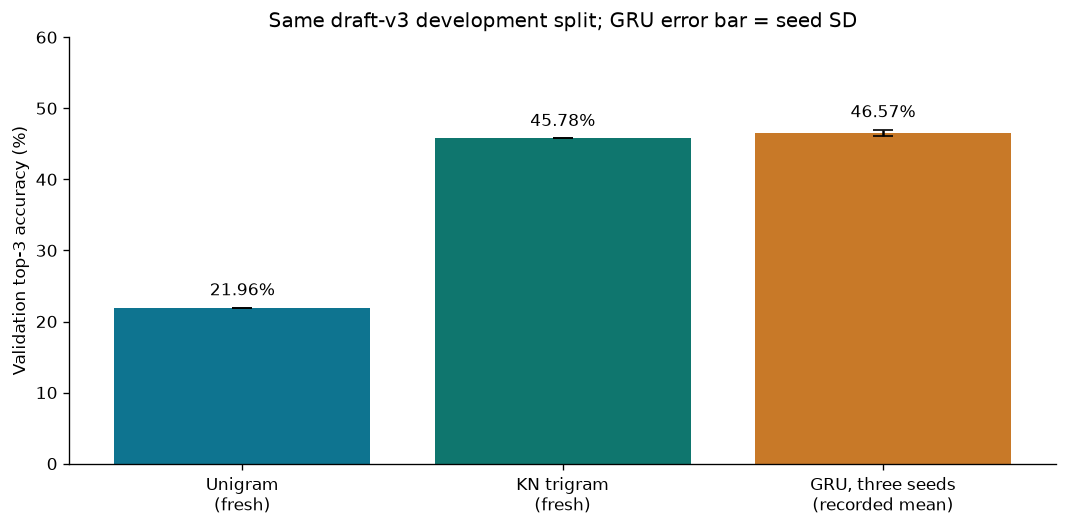

Recorded GRU mean minus trigram: 0.79 percentage points.
That small development difference alone does not justify a deployment choice.


In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
names = ["Unigram\n(fresh)", "KN trigram\n(fresh)", "GRU, three seeds\n(recorded mean)"]
values = [fresh_metrics["unigram"]["top3"], fresh_metrics["kn_trigram"]["top3"],
          gru_recorded["top3_mean"]]
errors = [0, 0, gru_recorded["top3_sd"]]
bars = ax.bar(names, np.asarray(values) * 100, yerr=np.asarray(errors) * 100,
              color=COLORS, capsize=6)
ax.bar_label(bars, labels=[f"{v:.2%}" for v in values], padding=5)
ax.set(ylabel="Validation top-3 accuracy (%)", ylim=(0, 60),
       title="Same draft-v3 development split; GRU error bar = seed SD")
fig.tight_layout()
plt.show()
difference = gru_recorded["top3_mean"] - fresh_metrics["kn_trigram"]["top3"]
print(f"Recorded GRU mean minus trigram: {difference * 100:.2f} percentage points.")
print("That small development difference alone does not justify a deployment choice.")

## 5. Error inspection and product implications

A useful suggestion model must help users compose intended messages. Aggregate accuracy alone cannot show whether a rare request is reachable or whether navigation requires fewer actions. This diagnostic separates first-symbol predictions from later context and shows six failures in fixed validation order; it does not choose flattering examples.

In [9]:
kn = models[1]
position_hits = Counter()
position_totals = Counter()
failures = []
for seq in validation:
    for i, target in enumerate(seq):
        prefix = seq[:i]
        guesses = kn.top_k(prefix, 3)
        bucket = "First symbol" if i == 0 else "With preceding symbols"
        position_totals[bucket] += 1
        position_hits[bucket] += int(target in guesses)
        if target not in guesses and len(failures) < 6:
            failures.append((" ".join(prefix) or "(start)", target, ", ".join(guesses)))
table(["Prediction position", "Events", "Trigram top-3"],
      [[bucket, total, f"{position_hits[bucket] / total:.2%}"]
       for bucket, total in position_totals.items()])
table(["Prefix", "True next symbol", "Incorrect top-3 suggestions"], failures)
rare_events = sum(count for symbol, count in val_counts.items() if train_counts[symbol] < 5)
print(f"Validation events for symbols observed fewer than 5 times in train: "
      f"{rare_events}/{sum(val_counts.values())} ({rare_events / sum(val_counts.values()):.1%}).")

| Prediction position | Events | Trigram top-3 |
| --- | --- | --- |
| First symbol | 319 | 51.41% |
| With preceding symbols | 1079 | 44.11% |

| Prefix | True next symbol | Incorrect top-3 suggestions |
| --- | --- | --- |
| (start) | ONLY | I, YOU, NOT |
| (start) | ONLY | I, YOU, NOT |
| (start) | ONLY | I, YOU, NOT |
| (start) | PHONE | I, YOU, NOT |
| (start) | FRIEND | I, YOU, NOT |
| I | LIKE | NOT, WANT, KNOW |

Validation events for symbols observed fewer than 5 times in train: 11/1398 (0.8%).


## 6. Existing deployment option and limitations

The existing candidate MVP is the browser board under `app/`. A user chooses pictures, sees next-symbol suggestions, composes a message and requests speech. The intended model path is a JSON trigram artifact or GRU ONNX loaded locally; manual board selection must remain available even when a suggestion is wrong. API routes in `api/` support server-side integration and a Swagger UI.

The export script is `ml/scripts/export_artifacts.py`. The present notebook validates model behavior on development data; it does not certify browser latency, offline speech availability, target-device performance or end-user accessibility. Those require a demonstration and target-device checks.

**Decision limits for the project review:**

- Only a small fraction of raw corpus lines map to the draft vocabulary. General text is not representative of AAC conversations.
- Generated lexical forms, symbol choices, pictograms and recorded Kinyarwanda pronunciations require native-speaker and practitioner review.
- Validation is repeatedly used during development. These results are provisional; keep the test partition sealed until model selection is frozen.
- Frequent symbols dominate accuracy; inspect rare communication needs and preserve manual access to the full board.
- The saved GRU advantage over the trigram is small. Model complexity should be justified by actual interaction benefit and device constraints.
- No clinical benefit, child usability improvement, study result or measured keystroke saving is claimed here.
- The final project direction is being reconsidered. This notebook preserves evidence for Vuga as an existing candidate, and does not imply that candidate has been selected.

In [10]:
summary = {
    "executed_utc": RUN_UTC,
    "status": "Existing Vuga prototype evidence; final project direction provisional",
    "split": "validation",
    "n_train": len(train),
    "n_validation": len(validation),
    "n_symbol_events": sum(val_counts.values()),
    "test_partition_opened": False,
    "lexicon_sha256": manifest["lexicon_sha256"],
    "snapshot_sha256": provenance["files_sha256"],
    "packages": VERSIONS,
    "fresh_statistical_metrics": fresh_metrics,
    "trigram_vs_unigram_paired_bootstrap": bootstrap,
    "recorded_gru_three_seed_summary": {
        key: gru_recorded[key] for key in
        ("top1_mean", "top3_mean", "top5_mean", "perplexity_mean", "top3_sd")
    },
    "fresh_optional_gru_onnx_seed0": gru_fresh,
}
summary_path = ML / "notebooks" / "validation_summary.json"
summary_path.write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
print("Saved:", summary_path.relative_to(REPO))
print("All notebook checks passed. No test examples were opened.")

Saved: ml\notebooks\validation_summary.json
All notebook checks passed. No test examples were opened.
